<center><h1>Zambrano_Claudia_HW5</h1></center>
<br>
<br>

Name: Claudia Zambrano
<br>
Github Username: claudia-z712
<br>
USC ID: 8224948861

## 1. Decision Trees as Interpretable Models

Import packages

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import (DecisionTreeClassifier,
                          DecisionTreeRegressor,
                          plot_tree,
                          export_text)
from sklearn import tree
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.linear_model import RidgeCV
from sklearn.linear_model import LassoCV
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold, cross_val_score
from sklearn.decomposition import PCA

### (a) Obtain Data

Get the Accute Inamations Data Set

In [5]:
# Load file, UTF-16 encoding and tab delimiter
dd = pd.read_csv('diagnosis.data.csv', encoding='utf-16', sep='\t', header=None)

# Fixing the data so its readable/usable
# change commas to decimal
df=dd.copy()
df[0] = df[0].str.replace(',', '.')

# convert to binary instead of yes or no
for col in range(1, 8):
    df[col] = df[col].map({'yes': 1, 'no': 0})

# Naming the columns
X = df[[0, 1, 2, 3, 4, 5]]
y1 = df[6]  # Inflamation of Urinary Bladder
y2 = df[7]  # Nephritis of renal pelvis origin
feature_names = ['Temp', 
                 "Nausea", 
                 "Lumbar_Pain", 
                 'Urine_Pushing', 
                 'Micturition_Pains', 
                 'Burning of urethra']

### (b) Build a decision tree

--- Decision Tree for Urinary Bladder Inflammation ---
|--- Urine_Pushing <= 0.50
|   |--- class: 0
|--- Urine_Pushing >  0.50
|   |--- Micturition_Pains <= 0.50
|   |   |--- Burning of urethra <= 0.50
|   |   |   |--- class: 1
|   |   |--- Burning of urethra >  0.50
|   |   |   |--- class: 0
|   |--- Micturition_Pains >  0.50
|   |   |--- class: 1



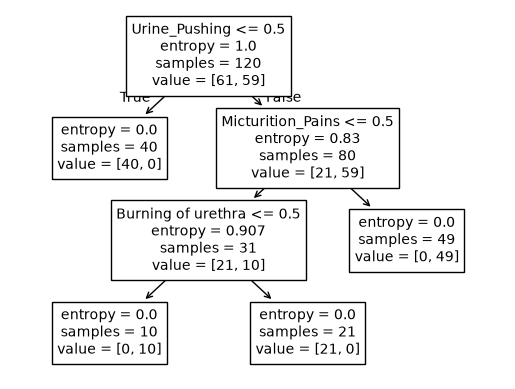

In [6]:
# Decision Tree for y1: Inflamation of Urinary Bladder
dt = tree.DecisionTreeClassifier(criterion='entropy')
dt.fit(X, y1)
tree.plot_tree(dt, feature_names=feature_names)

print("--- Decision Tree for Urinary Bladder Inflammation ---")
print(export_text(dt, feature_names=feature_names))

--- Decision Tree for Nephritis of Renal Pelvis Origin ---
|--- Temp <= 37.95
|   |--- class: 0
|--- Temp >  37.95
|   |--- Lumbar_Pain <= 0.50
|   |   |--- class: 0
|   |--- Lumbar_Pain >  0.50
|   |   |--- class: 1



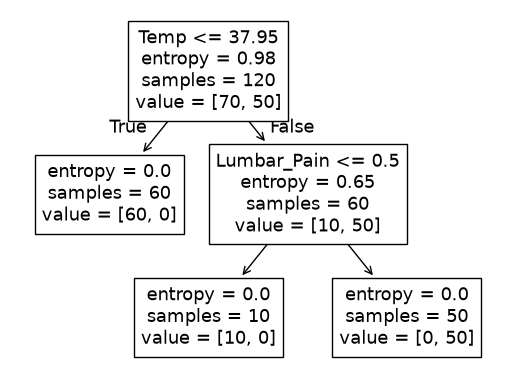

In [7]:
# Decision Tree for y2: Nephritis of renal pelvis origin
dn = tree.DecisionTreeClassifier(criterion='entropy')
dn.fit(X, y2)
tree.plot_tree(dn, feature_names=feature_names)

print("--- Decision Tree for Nephritis of Renal Pelvis Origin ---")
print(export_text(dn, feature_names=feature_names))

### (c) Convert the decision rules

In [8]:
def tree_to_pseudo(tree, feature_names):
	"""
	Outputs a decision tree model as if/then pseudocode
	
	Parameters:
	-----------
	tree: decision tree model
		The decision tree to represent as pseudocode
	feature_names: list
		The feature names of the dataset used for building the decision tree
	"""

	left = tree.tree_.children_left
	right = tree.tree_.children_right
	threshold = tree.tree_.threshold
	features = [feature_names[i] for i in tree.tree_.feature]
	value = tree.tree_.value

	def recurse(left, right, threshold, features, node, depth=0):
		indent = "  " * depth
		if (threshold[node] != -2):
			print(indent,"if ( " + features[node] + " <= " + str(threshold[node]) + " ) {")
			if left[node] != -1:
				recurse (left, right, threshold, features, left[node], depth+1)
				print(indent,"} else {")
				if right[node] != -1:
					recurse (left, right, threshold, features, right[node], depth+1)
				print(indent,"}")
		else:
			print(indent,"return " + str(value[node]))

	recurse(left, right, threshold, features, 0)

tree_to_pseudo(dt, feature_names)

 if ( Urine_Pushing <= 0.5 ) {
   return [[1. 0.]]
 } else {
   if ( Micturition_Pains <= 0.5 ) {
     if ( Burning of urethra <= 0.5 ) {
       return [[0. 1.]]
     } else {
       return [[1. 0.]]
     }
   } else {
     return [[0. 1.]]
   }
 }


### 1.4 (d) Pruning

Optimal alpha for pruning: 0.0000
Pruned Tree Accuracy: 1.0000

--- Interpretable Decision Rules for Pruned Tree ---
 if ( Urine_Pushing <= 0.5 ) {
   return [[1. 0.]]
 } else {
   if ( Micturition_Pains <= 0.5 ) {
     if ( Burning of urethra <= 0.5 ) {
       return [[0. 1.]]
     } else {
       return [[1. 0.]]
     }
   } else {
     return [[0. 1.]]
   }
 }


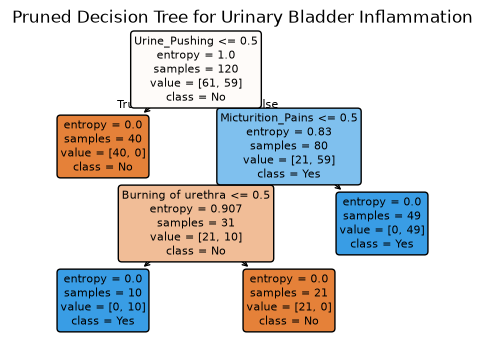

In [9]:
path = dt.cost_complexity_pruning_path(X, y1)
ccp_alphas, impurities = path.ccp_alphas, path.impurities

# Find the optimal alpha. Since the dataset is extremely small and separable,
# we can inspect the alphas. We want a minimal tree that maintains perfect or high accuracy.
clfs = []
for ccp_alpha in ccp_alphas:
    clf = DecisionTreeClassifier(random_state=42, criterion='entropy', ccp_alpha=ccp_alpha)
    clf.fit(X, y1)
    clfs.append(clf)

# We filter for trees that still maintain the best possible accuracy or a high accuracy 
# while maximizing ccp_alpha (which minimizes tree complexity)
scores = [clf.score(X, y1) for clf in clfs]
best_idx = max([i for i, score in enumerate(scores) if score == max(scores)])
best_alpha = ccp_alphas[best_idx]

# Fit the final pruned tree
dt_pruned = DecisionTreeClassifier(random_state=42, criterion='entropy', ccp_alpha=best_alpha)
dt_pruned.fit(X, y1)

# Display the results
print(f"Optimal alpha for pruning: {best_alpha:.4f}")
print(f"Pruned Tree Accuracy: {dt_pruned.score(X, y1):.4f}\n")

print("--- Interpretable Decision Rules for Pruned Tree ---")
tree_to_pseudo(dt_pruned, feature_names)

# Plot the pruned tree
plt.figure(figsize=(6, 4))
plot_tree(dt_pruned, feature_names=feature_names, class_names=['No', 'Yes'], filled=True, rounded=True)
plt.title("Pruned Decision Tree for Urinary Bladder Inflammation")
plt.show()

## 2. The LASSO and Boosting for Regression

### (a) Obtain Data

In [10]:
import re
import pandas as pd

# Extract attribute names from communities.names
headers = []
with open('communities.names', 'r') as f:
    for line in f:
        # Look for lines starting with '@attribute'
        match = re.match(r'@attribute\s+(\S+)', line)
        if match:
            headers.append(match.group(1))

# Load the data file with the extracted headers
df_communities = pd.read_csv('communities.data', header=None, names=headers)

# Display the first 5 lines
df_communities.head(5)

,state,county,community,communityname,fold,population,householdsize,racepctblack,racePctWhite,racePctAsian,...,LandArea,PopDens,PctUsePubTrans,PolicCars,PolicOperBudg,LemasPctPolicOnPatr,LemasGangUnitDeploy,LemasPctOfficDrugUn,PolicBudgPerPop,ViolentCrimesPerPop
0,8,?,?,Lakewoodcity,1,0.19,0.33,0.02,0.90,0.12,...,0.12,0.26,0.20,0.06,0.04,0.9,0.5,0.32,0.14,0.20
1,53,?,?,Tukwilacity,1,0.00,0.16,0.12,0.74,0.45,...,0.02,0.12,0.45,?,?,?,?,0.00,?,0.67
2,24,?,?,Aberdeentown,1,0.00,0.42,0.49,0.56,0.17,...,0.01,0.21,0.02,?,?,?,?,0.00,?,0.43
3,34,5,81440,Willingborotownship,1,0.04,0.77,1.00,0.08,0.12,...,0.02,0.39,0.28,?,?,?,?,0.00,?,0.12
4,42,95,6096,Bethlehemtownship,1,0.01,0.55,0.02,0.95,0.09,...,0.04,0.09,0.02,?,?,?,?,0.00,?,0.03


### (b) Missing values

In [11]:
import numpy as np

df_imputed = df_communities.copy()

# Replace ? with NaN
df_imputed = df_imputed.replace('?', np.nan)

columns_to_impute = [col for col in df_imputed.columns if col not in ['county', 'community', 'communityname']]

for col in columns_to_impute:
    # Convert columns to numeric
    df_imputed[col] = pd.to_numeric(df_imputed[col], errors='coerce')
    # Calculate the median for that column
    median_val = df_imputed[col].median()
    # Fill NaNs with the median
    df_imputed[col] = df_imputed[col].fillna(median_val)

# Display Data
df_imputed.head(5)

,state,county,community,communityname,fold,population,householdsize,racepctblack,racePctWhite,racePctAsian,...,LandArea,PopDens,PctUsePubTrans,PolicCars,PolicOperBudg,LemasPctPolicOnPatr,LemasGangUnitDeploy,LemasPctOfficDrugUn,PolicBudgPerPop,ViolentCrimesPerPop
0,8,NaN,NaN,Lakewoodcity,1,0.19,0.33,0.02,0.90,0.12,...,0.12,0.26,0.20,0.06,0.04,0.90,0.5,0.32,0.14,0.20
1,53,NaN,NaN,Tukwilacity,1,0.00,0.16,0.12,0.74,0.45,...,0.02,0.12,0.45,0.08,0.03,0.75,0.5,0.00,0.15,0.67
2,24,NaN,NaN,Aberdeentown,1,0.00,0.42,0.49,0.56,0.17,...,0.01,0.21,0.02,0.08,0.03,0.75,0.5,0.00,0.15,0.43
3,34,5,81440,Willingborotownship,1,0.04,0.77,1.00,0.08,0.12,...,0.02,0.39,0.28,0.08,0.03,0.75,0.5,0.00,0.15,0.12
4,42,95,6096,Bethlehemtownship,1,0.01,0.55,0.02,0.95,0.09,...,0.04,0.09,0.02,0.08,0.03,0.75,0.5,0.00,0.15,0.03


### (c) Plot a correlation matrix

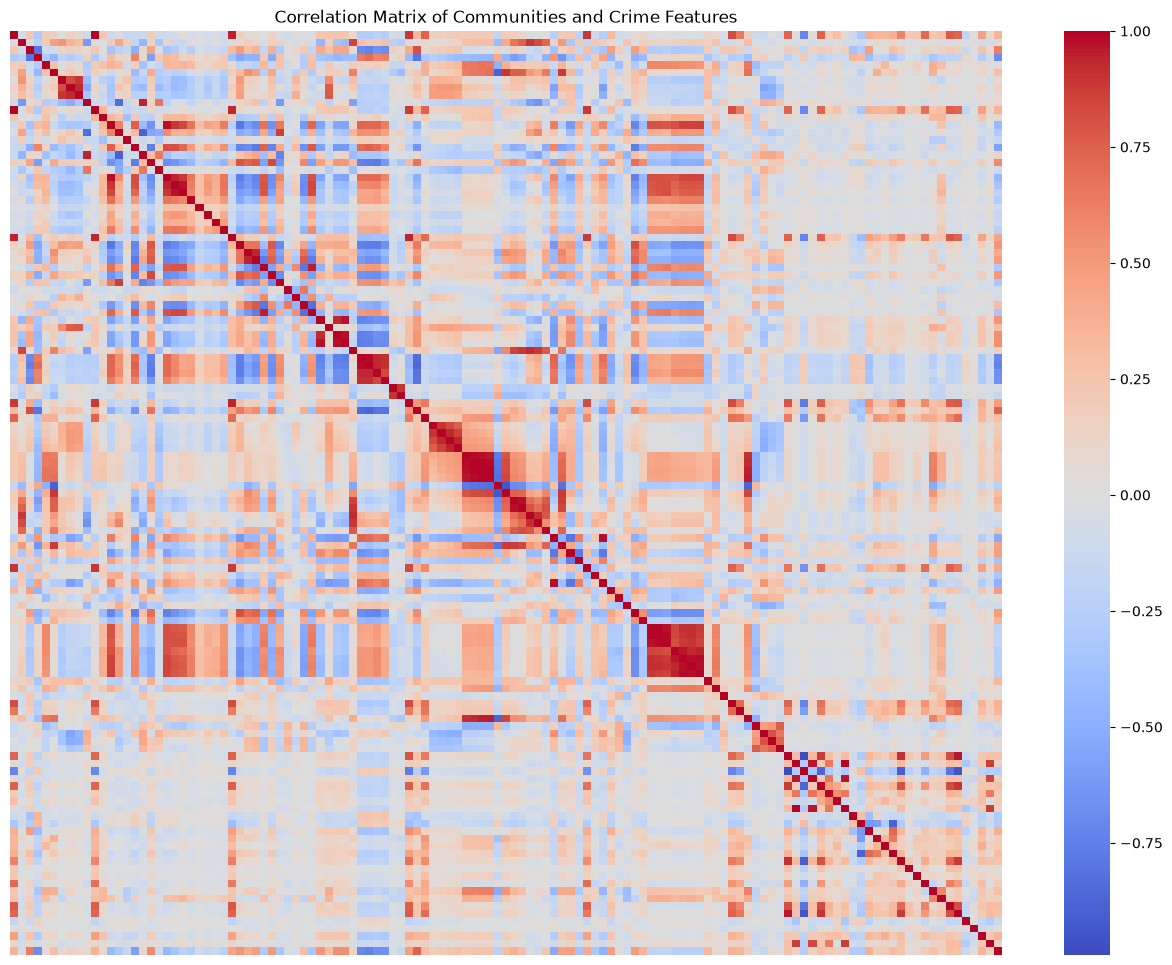

In [12]:
# Not using numeric data from the state, county, community name and fold
# Start from population column
population_idx = df_imputed.columns.get_loc('population')
df_selected = df_imputed.iloc[:, population_idx:]
# Make correlation matrix
corr_matrix = df_selected.corr()

# Plot
plt.figure(figsize=(16, 12))

# Using heatmap because there are alot of features
sns.heatmap(corr_matrix, cmap='coolwarm', xticklabels=False, yticklabels=False)

plt.title('Correlation Matrix of Communities and Crime Features')
plt.show()

### (d) Calculate the Coefficient of Variation CV

In [13]:
# Calculate mean and standard deviation
means = df_selected.mean()
stds = df_selected.std()

# Calculate Coefficient of Variation (CV = std / mean)
# Using fillna(0) in case any mean is 0 to avoid division by zero issues
cv_series = (stds / means).fillna(0)

# Create a DataFrame to present the results cleanly
df_cv = pd.DataFrame({
    'Mean': means,
    'Std Dev': stds,
    'CV': cv_series
}).sort_values(by='CV', ascending=False)

display(df_cv)

,Mean,Std Dev,CV
PctPolicAsian,0.018375,0.100105,5.447835
NumStreet,0.022778,0.100400,4.407702
NumInShelters,0.029438,0.102607,3.485481
NumIlleg,0.036294,0.108671,2.994196
NumImmig,0.030060,0.087189,2.900497
...,...,...,...
NumKindsDrugsSeiz,0.567768,0.081320,0.143227
RacialMatchCommPol,0.731906,0.092479,0.126354
LemasPctPolicOnPatr,0.741775,0.087514,0.117979
PctPolicWhite,0.771515,0.090554,0.117372


### (e) Scatter plots and box plots for highest CV features

Top 11 Features with highest CV: ['PctPolicAsian', 'NumStreet', 'NumInShelters', 'NumIlleg', 'NumImmig', 'LemasPctOfficDrugUn', 'NumUnderPov', 'population', 'LemasSwornFT', 'numbUrban', 'HousVacant']


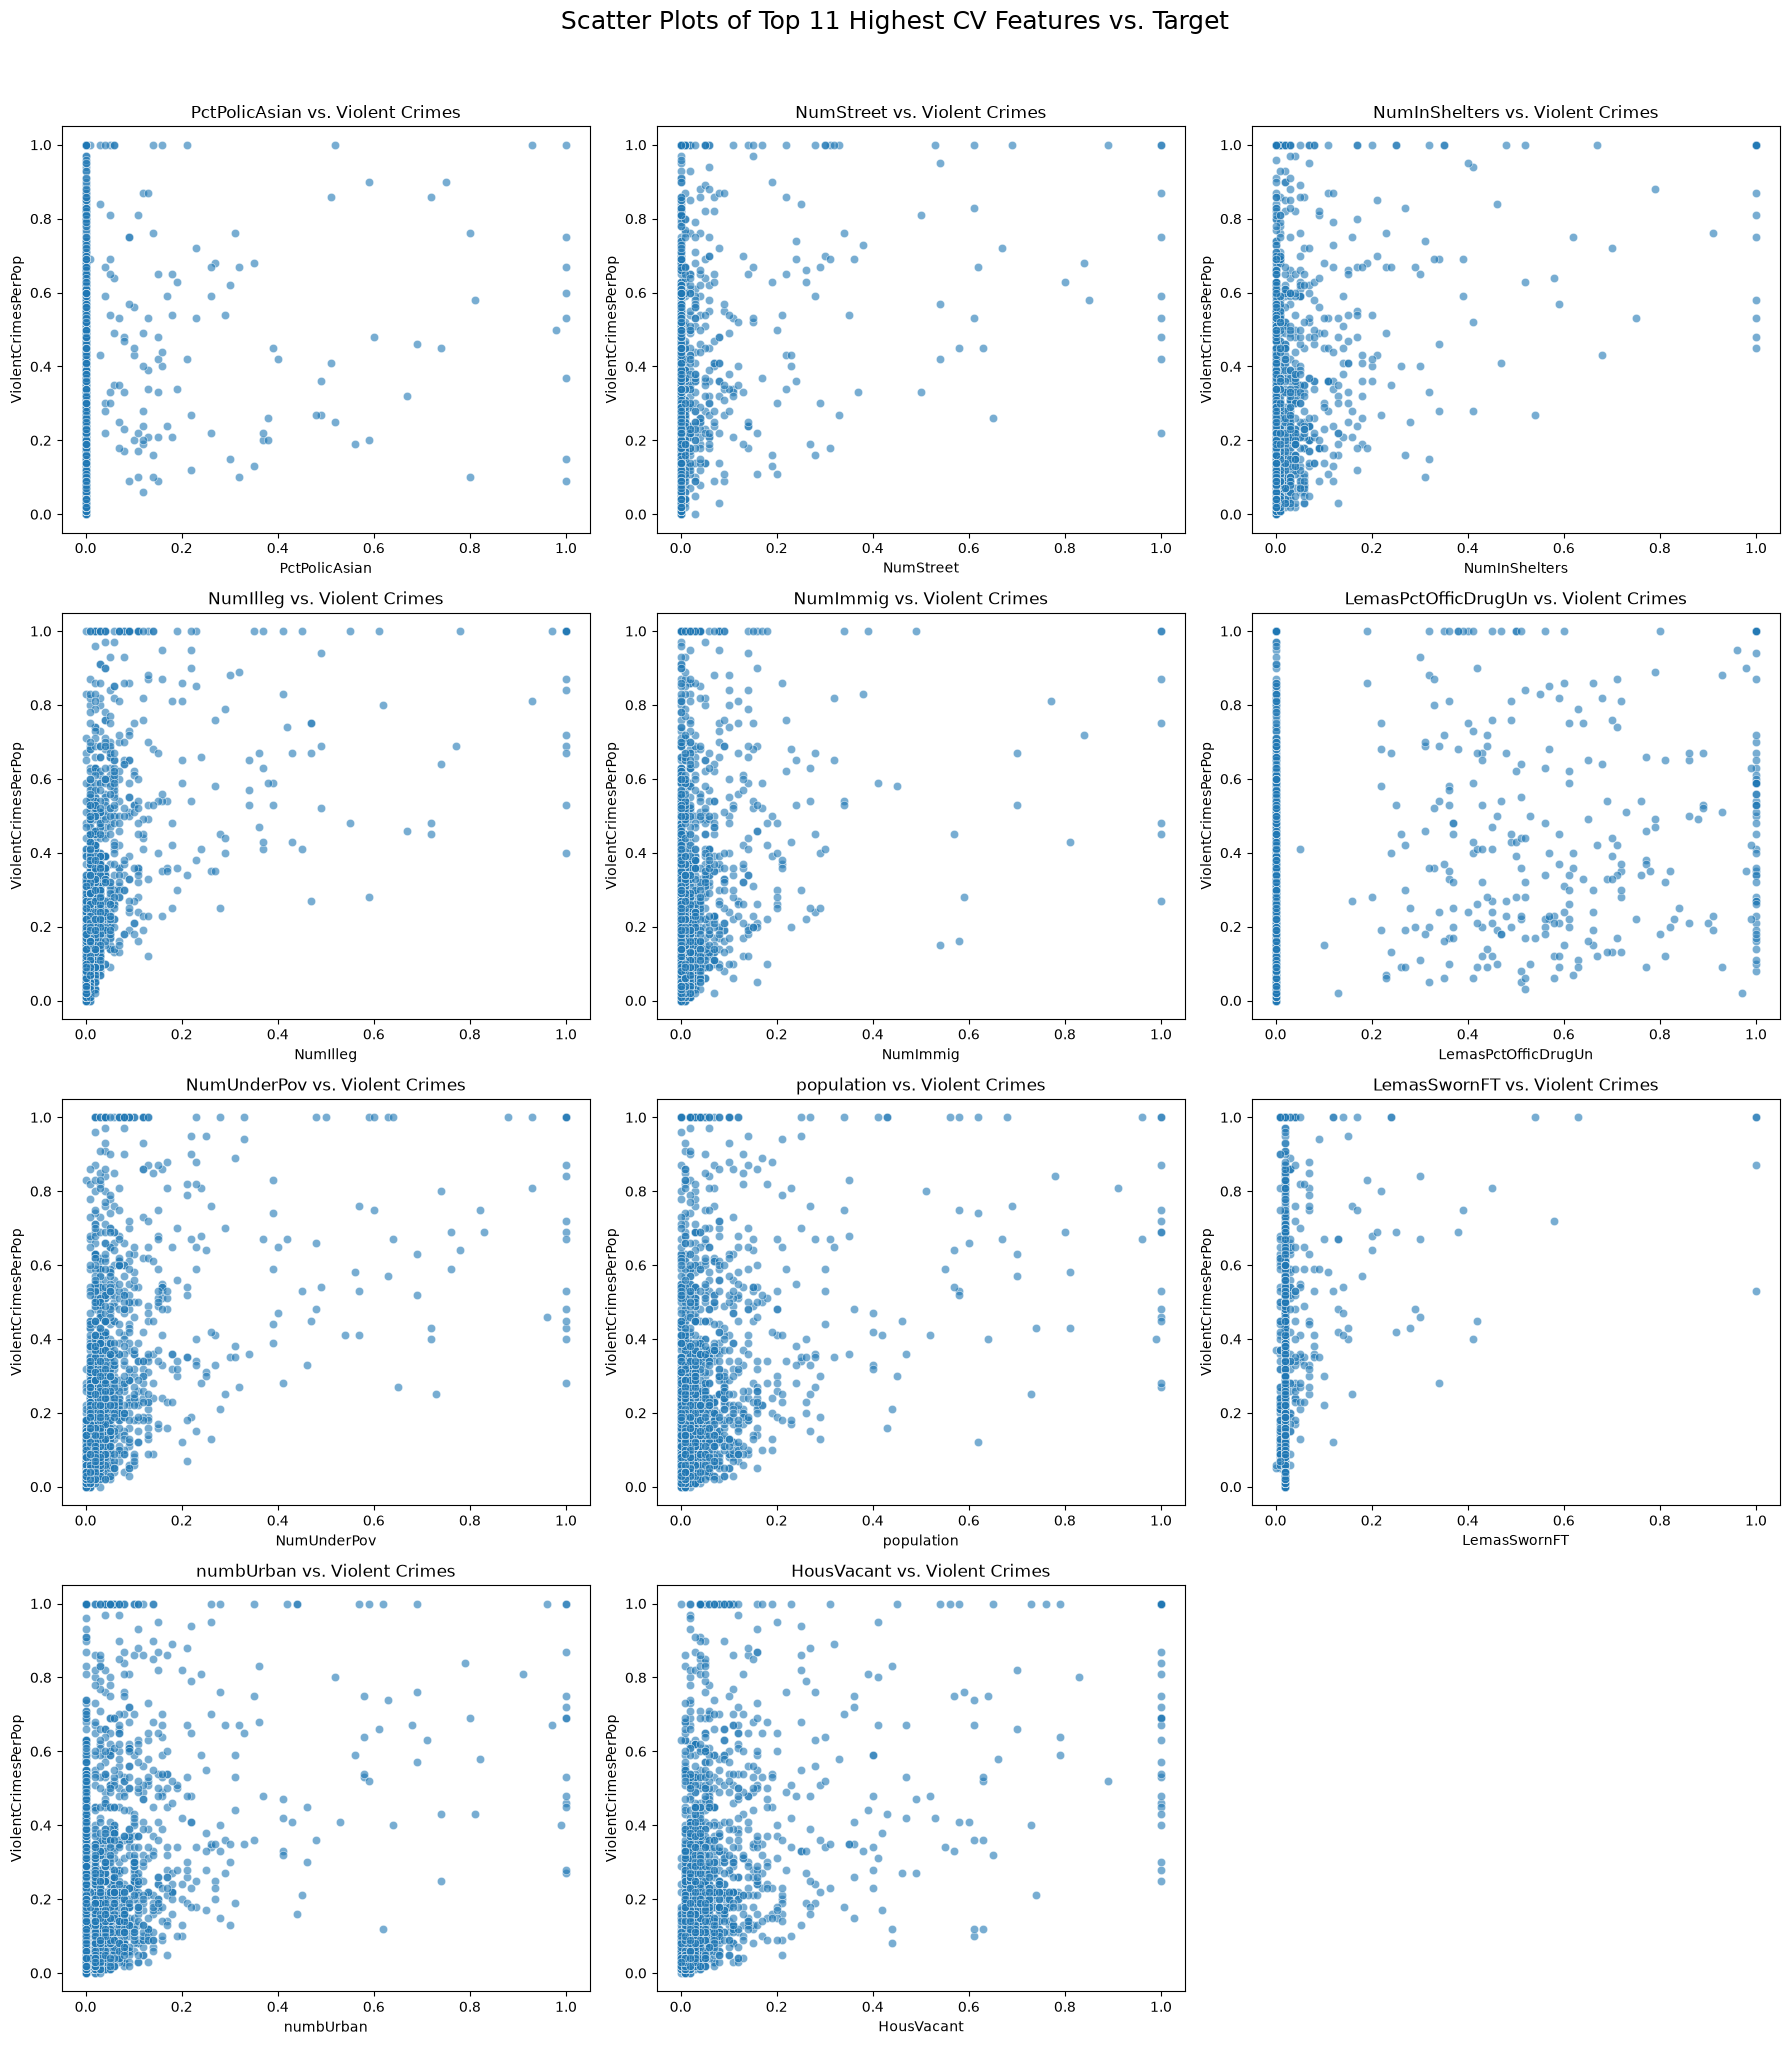

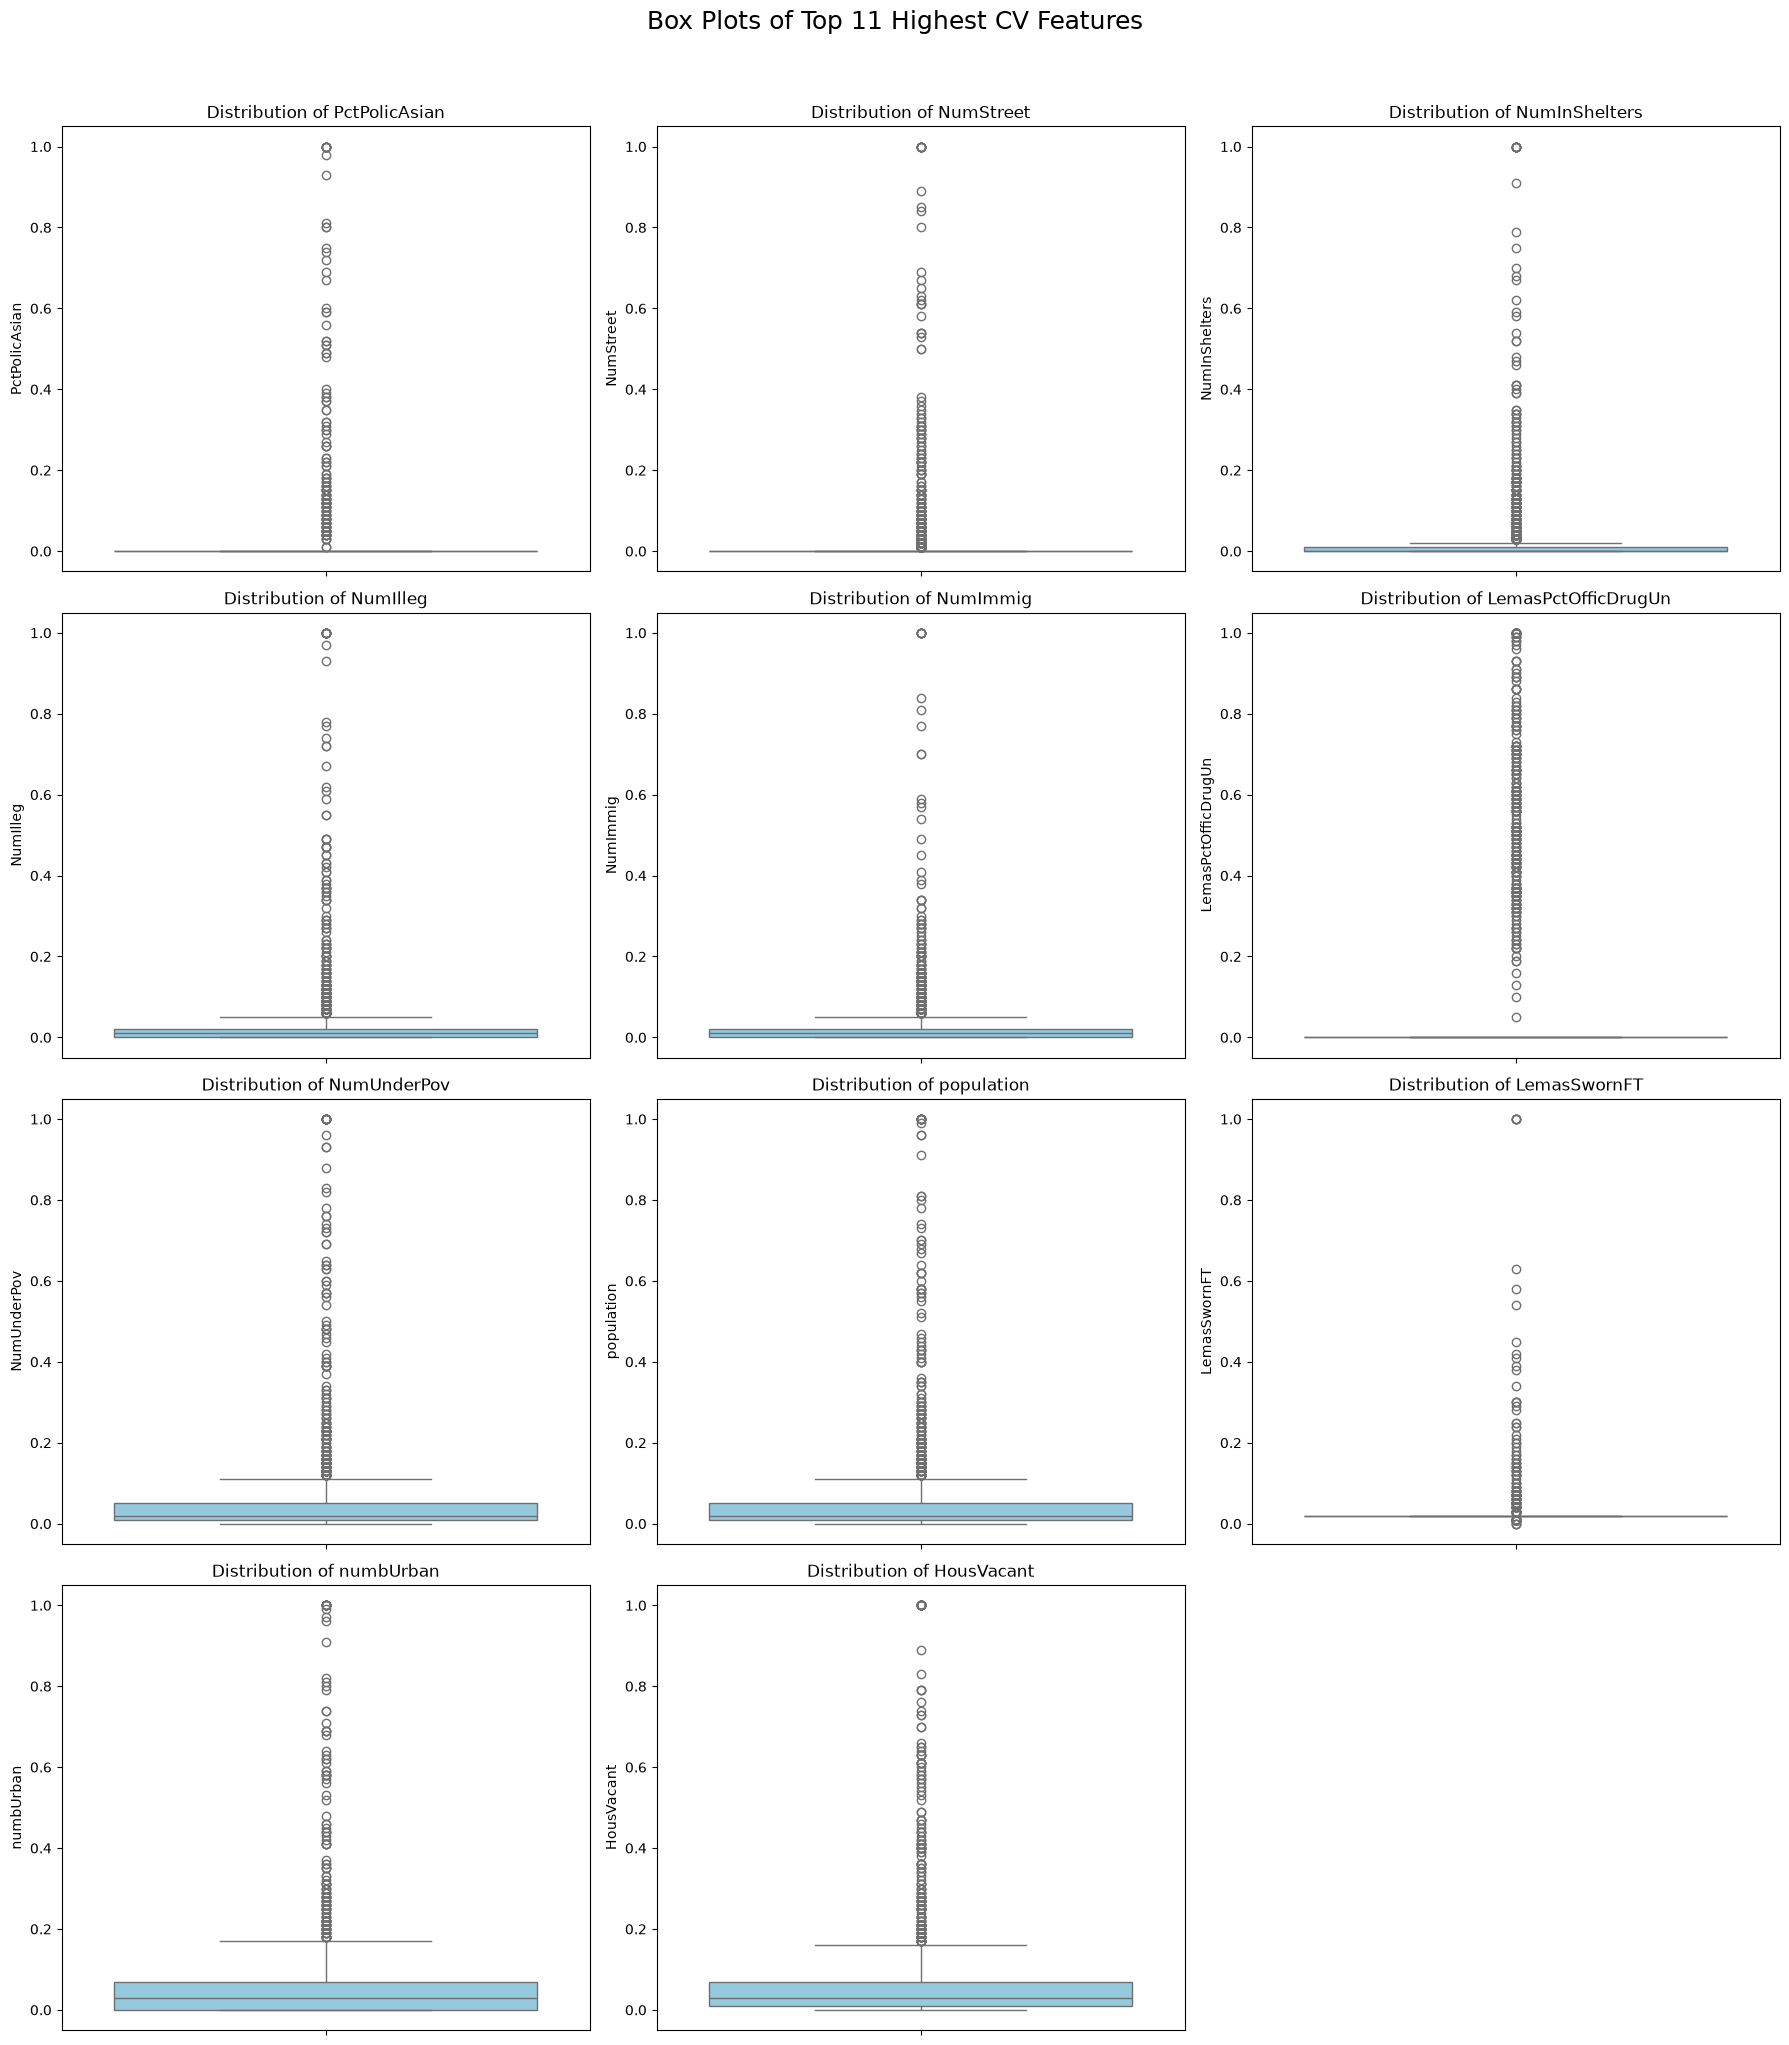

Wouldn't say we can make solid conclusions based of these, since there was quite alot of missing data


In [14]:
# Top 11 features with the highest CV (rounding to the nearest whole number)
# Excluding Violent Crimes if it's in the top 11 since its the target
top_11_features = df_cv[df_cv.index != 'ViolentCrimesPerPop'].head(11).index.tolist()

print("Top 11 Features with highest CV:", top_11_features)

# Create subplots for Scatter Plots (Feature vs. ViolentCrimesPerPop)
fig, axes = plt.subplots(4, 3, figsize=(18, 20))
axes = axes.flatten()

for i, feature in enumerate(top_11_features):
    sns.scatterplot(data=df_selected, x=feature, y='ViolentCrimesPerPop', ax=axes[i], alpha=0.6)
    axes[i].set_title(f'{feature} vs. Violent Crimes')
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel('ViolentCrimesPerPop')

# Turn off any unused subplot axes
for j in range(len(top_11_features), len(axes)):
    fig.delaxes(axes[j])

plt.suptitle('Scatter Plots of Top 11 Highest CV Features vs. Target', fontsize=18, y=1.02)
plt.tight_layout()
plt.show()

# Create subplots for Box Plots to show distributions
fig, axes = plt.subplots(4, 3, figsize=(18, 20))
axes = axes.flatten()

for i, feature in enumerate(top_11_features):
    sns.boxplot(data=df_selected, y=feature, ax=axes[i], color='skyblue')
    axes[i].set_title(f'Distribution of {feature}')
    axes[i].set_ylabel(feature)

# Turn off any unused subplot axes
for j in range(len(top_11_features), len(axes)):
    fig.delaxes(axes[j])

plt.suptitle('Box Plots of Top 11 Highest CV Features', fontsize=18, y=1.02)
plt.tight_layout()
plt.show()

print("Wouldn't say we can make solid conclusions based of these, since there was quite alot of missing data") 

### (f) Fit a linear model

In [15]:
# Split features and target
X_sel = df_selected.drop(columns=['ViolentCrimesPerPop'])
y_sel = df_selected['ViolentCrimesPerPop']

# Train-test split (first 1495 rows for training, remainder for testing)
X_train = X_sel.iloc[:1495]
X_test = X_sel.iloc[1495:]
y_train = y_sel.iloc[:1495]
y_test = y_sel.iloc[1495:]

# Initialize and fit the least squares linear regression model
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

# Predict and calculate test error (Mean Squared Error)
y_pred = lr_model.predict(X_test)
test_mse = mean_squared_error(y_test, y_pred)

print(f"Least Squares Linear Regression Test MSE: {test_mse:.6f}")

Least Squares Linear Regression Test MSE: 0.017977


### (g) Fit a ridge regression model

In [16]:
# Define a range of alphas (lambdas) to test in cross-validation
alphas = np.logspace(-4, 4, 100)

# Initialize and fit Ridge Regression with 5-fold cross-validation
ridge_cv = RidgeCV(alphas=alphas, cv=5, scoring='neg_mean_squared_error')
ridge_cv.fit(X_train, y_train)

# Best regularization parameter
best_alpha = ridge_cv.alpha_

# Predict on test set
y_pred_ridge = ridge_cv.predict(X_test)
test_mse_ridge = mean_squared_error(y_test, y_pred_ridge)

print(f"Optimal alpha (lambda) chosen by CV: {best_alpha:.6f}")
print(f"Ridge Regression Test MSE: {test_mse_ridge:.6f}")

Optimal alpha (lambda) chosen by CV: 2.310130
Ridge Regression Test MSE: 0.017517


### (h) Fit a LASSO model

In [17]:
# LassoCV automatically searches over an efficiently selected range of alphas
lasso_cv = LassoCV(cv=5, random_state=42, max_iter=10000)
lasso_cv.fit(X_train, y_train)

# Best regularization parameter
best_alpha_lasso = lasso_cv.alpha_

# Predict on test set
y_pred_lasso = lasso_cv.predict(X_test)
test_mse_lasso = mean_squared_error(y_test, y_pred_lasso)

# Get selected variables (non-zero coefficients)
feature_names = X_train.columns
coefs = lasso_cv.coef_
selected_features = [feature_names[i] for i, coef in enumerate(coefs) if coef != 0]

print(f"Optimal alpha (lambda) chosen by LASSO CV: {best_alpha_lasso:.6f}")
print(f"LASSO Regression Test MSE: {test_mse_lasso:.6f}")
print(f"Number of variables selected: {len(selected_features)} / {len(feature_names)}")
print(" \n Selected Variables:", selected_features)

Optimal alpha (lambda) chosen by LASSO CV: 0.000125
LASSO Regression Test MSE: 0.017620
Number of variables selected: 74 / 122
 
 Selected Variables: ['racepctblack', 'racePctAsian', 'agePct12t21', 'agePct12t29', 'pctUrban', 'pctWWage', 'pctWFarmSelf', 'pctWInvInc', 'pctWSocSec', 'pctWPubAsst', 'pctWRetire', 'whitePerCap', 'blackPerCap', 'indianPerCap', 'AsianPerCap', 'OtherPerCap', 'HispPerCap', 'PctPopUnderPov', 'PctLess9thGrade', 'PctEmploy', 'PctEmplManu', 'PctOccupManu', 'MalePctDivorce', 'MalePctNevMarr', 'FemalePctDiv', 'PctKids2Par', 'PctYoungKids2Par', 'PctTeen2Par', 'PctWorkMom', 'NumIlleg', 'PctIlleg', 'NumImmig', 'PctImmigRecent', 'PctImmigRec10', 'PctRecImmig10', 'PctNotSpeakEnglWell', 'PctLargHouseOccup', 'PersPerOccupHous', 'PctPersOwnOccup', 'PctPersDenseHous', 'PctHousLess3BR', 'MedNumBR', 'HousVacant', 'PctHousOccup', 'PctVacantBoarded', 'PctVacMore6Mos', 'MedYrHousBuilt', 'PctHousNoPhone', 'PctWOFullPlumb', 'OwnOccLowQuart', 'RentLowQ', 'MedRent', 'MedRentPctHousInc'

### (i) Fit a PCR model

In [18]:
# Define 5-fold CV split
kf = KFold(n_splits=5, shuffle=True, random_state=42)

cv_errors = []

# Test M from 1 to the maximum number of components (122)
max_components = X_train.shape[1]
components_range = range(1, max_components + 1)

for m in components_range:
    # Project to first M principal components directly from X_train
    pca = PCA(n_components=m)
    X_train_pca = pca.fit_transform(X_train)
    
    # Instantiate linear regression
    lr = LinearRegression()
    
    # Compute 5-fold cross-validation negative MSE
    scores = cross_val_score(lr, X_train_pca, y_train, cv=kf, scoring='neg_mean_squared_error')
    cv_errors.append(-np.mean(scores))

# Find optimal number of components M
optimal_m = components_range[np.argmin(cv_errors)]
min_cv_error = min(cv_errors)

# Train the final PCR model on the full training set using optimal M
pca_opt = PCA(n_components=optimal_m)
X_train_pca_opt = pca_opt.fit_transform(X_train)
X_test_pca_opt = pca_opt.transform(X_test)

pcr_model = LinearRegression()
pcr_model.fit(X_train_pca_opt, y_train)

# Predict on test set and calculate test error
y_pred_pcr = pcr_model.predict(X_test_pca_opt)
test_mse_pcr = mean_squared_error(y_test, y_pred_pcr)

print(f"Optimal number of principal components (M) chosen by CV: {optimal_m}")
print(f"PCR Training CV MSE for optimal M: {min_cv_error:.6f}")
print(f"PCR Test MSE: {test_mse_pcr:.6f}")

Optimal number of principal components (M) chosen by CV: 47
PCR Training CV MSE for optimal M: 0.019999
PCR Test MSE: 0.018411
